# 08 - Out-of-sample validation (Test 6)

**Research question.** Do optimised portfolios beat naive ones *out of sample*, net of costs, and is any difference statistically and economically meaningful?

**Protocol (no look-ahead by construction).** At each rebalance date $i$ estimate on rows $[i-W,i)$ (rolling) or $[0,i)$ (expanding); hold for the next 21 days with weights drifting; charge $c\cdot$turnover on the first day of each holding period. The unit tests in `tests/test_core.py` verify that corrupting *future* data does not change past weights.

Parameters to vary and justify: window $W$, rebalance frequency, cost level, rolling vs expanding.

In [1]:
import sys, warnings
import os
from pathlib import Path
try: 
    os.chdir(Path(__vsc_ipynb_file__).resolve().parent)
except NameError:  
    pass
sys.path.insert(0, os.path.abspath(".."))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import data_processing as dp, covariance_estimators as ce, portfolio_models as pm
from src import stability_tests as st, regime_detection as rd, stress_testing as sx, evaluation as ev
from src.backtesting import walk_forward, make_models, in_sample_vs_out_of_sample
plt.rcParams["figure.dpi"] = 110
TABLE_DIR = Path("../results/tables")
FIGURE_DIR = Path("../results/figures")
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

_candidates = ["returns_simple_daily.csv"]
_path = next((Path("../data/processed") / f for f in _candidates if (Path("../data/processed") / f).exists()), None)
if _path is None:
    raise FileNotFoundError("Run notebook 01 first: expected ../data/processed/returns_simple_daily.csv")
returns = pd.read_csv(_path, index_col=0, parse_dates=True)
print("loaded:", _path.name)
X = returns.to_numpy()
WINDOW = 504
print(returns.shape, returns.index[0].date(), "->", returns.index[-1].date())

loaded: returns_simple_daily.csv
(3519, 5) 2012-01-04 -> 2025-12-31


## 1. Baseline walk-forward (rolling 504d, monthly, 10 bps)

In [2]:
models = make_models({m: pm.MODELS[m].fn for m in pm.CORE_TEN})
res = walk_forward(returns, models, window=WINDOW, rebalance_every=21, cost_bps=10)
print("model failures (fell back to previous weights):", res.failures)
perf = ev.performance_table(res.net_returns, res.mean_turnover(), res.mean_effective_n())
perf_summary = perf.sort_values("sharpe", ascending=False).round(3)
perf_summary.to_csv(TABLE_DIR / "oos_performance_summary.csv", index_label="model")
perf_summary

model failures (fell back to previous weights): {'equal_weight': 0, 'gmv_long_only': 0, 'mean_variance': 0, 'max_sharpe': 0, 'min_vol_capped': 0, 'ledoit_wolf_minvar': 0, 'robust_mv': 0, 'risk_parity': 0, 'black_litterman': 0, 'cond_vol_minvar': 0}


,ann_return,ann_vol,sharpe,sortino,max_drawdown,calmar,VaR_5%,CVaR_5%,avg_turnover_per_rebalance,avg_effective_N
min_vol_capped,0.086,0.096,0.912,1.276,-0.211,0.409,0.009,0.014,0.019,4.373
risk_parity,0.064,0.071,0.909,1.281,-0.179,0.355,0.007,0.010,0.012,3.047
mean_variance,0.072,0.090,0.818,1.135,-0.199,0.360,0.009,0.014,0.073,2.575
equal_weight,0.083,0.107,0.798,1.112,-0.235,0.353,0.010,0.016,0.011,5.000
ledoit_wolf_minvar,0.037,0.052,0.722,0.995,-0.168,0.218,0.005,0.008,0.013,1.335
max_sharpe,0.067,0.101,0.696,0.992,-0.244,0.276,0.009,0.016,0.095,1.804
robust_mv,0.074,0.111,0.693,0.953,-0.247,0.297,0.011,0.018,0.114,1.974
gmv_long_only,0.030,0.051,0.604,0.829,-0.177,0.168,0.005,0.007,0.009,1.196
cond_vol_minvar,0.028,0.050,0.570,0.780,-0.190,0.146,0.005,0.007,0.086,1.331
black_litterman,0.060,0.151,0.465,0.633,-0.283,0.213,0.015,0.023,0.181,1.800


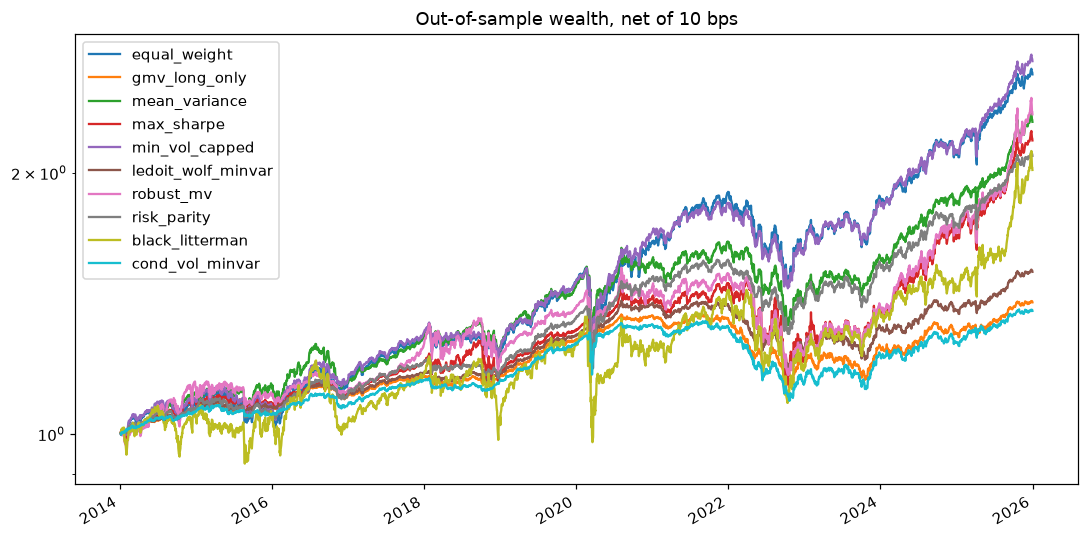

In [3]:
ax = (1 + res.net_returns).cumprod().plot(logy=True, figsize=(10, 5), title="Out-of-sample wealth, net of 10 bps")
fig = ax.get_figure()
plt.tight_layout()
fig.savefig(FIGURE_DIR / "oos_wealth_net_of_costs.png", dpi=150, bbox_inches="tight")

## 2. In-sample promise vs out-of-sample outcome

In [4]:
gap = in_sample_vs_out_of_sample(res, ev.sharpe_ratio)
gap_summary = gap.sort_values("gap", ascending=False).round(3)
gap_summary.to_csv(TABLE_DIR / "in_sample_vs_out_of_sample_sharpe_gap.csv", index_label="model")
gap_summary

,in_sample_sharpe,oos_sharpe_gross,gap
max_sharpe,1.450,0.719,0.732
robust_mv,1.327,0.718,0.609
black_litterman,1.079,0.494,0.586
mean_variance,1.250,0.838,0.412
cond_vol_minvar,0.814,0.612,0.203
gmv_long_only,0.798,0.608,0.189
ledoit_wolf_minvar,0.910,0.728,0.182
risk_parity,0.893,0.913,-0.020
equal_weight,0.767,0.800,-0.033
min_vol_capped,0.853,0.917,-0.063


**Interpret:** `gap` = average ex-ante Sharpe at the time of optimisation minus realised gross out-of-sample Sharpe. This is the *optimisation overfit*. Which models over-promise most? Relate to the inputs each uses.

The main pattern is that **models relying most directly on estimated returns show the largest in-sample optimism**. The `gap` is measured in Sharpe units, not percent.

- **Largest gaps:** max-Sharpe (**0.732**), robust mean-variance (**0.609**), and Black–Litterman (**0.586**). Max-Sharpe’s in-sample Sharpe of **1.450** falls to **0.719** out of sample. Robust MV lands at **0.718**; Black–Litterman has the lowest OOS Sharpe in the table, **0.494**.
- **Intermediate:** mean-variance has a **0.412** gap, but the highest OOS Sharpe among these four at **0.838**.
- **Smaller gaps:** conditional-volatility minimum variance (**0.203**), GMV (**0.189**), and Ledoit–Wolf minimum variance (**0.182**).
- **Negative gaps:** risk parity (**−0.020**), equal weight (**−0.033**), and capped minimum volatility (**−0.063**) did slightly better out of sample than their average ex-ante Sharpe suggested.

This is consistent with the models’ inputs: max-Sharpe and mean-variance use estimated means directly; robust MV still uses sample means, despite its robustness penalty; and Black–Litterman’s sample-driven views temper, but do not eliminate, mean-estimation risk. Covariance-focused methods generally have smaller gaps, while equal weight does not estimate an optimal allocation from the sample.

A negative gap is **not proof of no overfitting**—it can arise from ordinary variation between the estimation and test periods. All reported OOS Sharpes are positive, but they are **gross**, before costs, and the table alone does not establish that differences are statistically meaningful or will persist.

## 3. Is any outperformance statistically significant? (stationary block bootstrap)

In [5]:
rows = {}
for m in res.net_returns.columns:
    if m == "equal_weight": continue
    d = ev.bootstrap_sharpe_difference(res.net_returns[m], res.net_returns["equal_weight"], n_boot=1000, mean_block=10)
    d["CE_gain_gamma5_ann"] = ev.economic_significance(res.net_returns[m], res.net_returns["equal_weight"], gamma=5)
    rows[m] = d
cmp_ = pd.DataFrame(rows).T
cmp_["CI_excludes_0"] = (cmp_["ci_low"] > 0) | (cmp_["ci_high"] < 0)
bootstrap_comparison = cmp_.round(3)
bootstrap_comparison.to_csv(TABLE_DIR / "oos_sharpe_bootstrap_comparison.csv", index_label="model")
bootstrap_comparison

,diff,ci_low,ci_high,p_value,CE_gain_gamma5_ann,CI_excludes_0
gmv_long_only,-0.194,-0.659,0.210,0.404,-0.033,False
mean_variance,0.020,-0.283,0.285,0.884,-0.004,False
max_sharpe,-0.102,-0.533,0.297,0.618,-0.012,False
min_vol_capped,0.114,0.011,0.223,0.036,0.008,True
ledoit_wolf_minvar,-0.076,-0.501,0.305,0.706,-0.026,False
robust_mv,-0.105,-0.509,0.263,0.604,-0.011,False
risk_parity,0.111,-0.099,0.292,0.253,-0.005,False
black_litterman,-0.333,-0.649,-0.044,0.032,-0.044,True
cond_vol_minvar,-0.228,-0.657,0.172,0.284,-0.035,False


**Interpret (statistical vs economic):**
- Compare `p_value` and the CI with `CE_gain_gamma5_ann` (certainty-equivalent gain in annual return units for $\gamma=5$). Can a result be significant but economically trivial? Or large but insignificant?
- With ~10 models you are making ~9 comparisons: how does multiple testing change what you can claim? (Name at least one correction and apply a simple Bonferroni threshold to the p-values.)

- **Capped minimum volatility** is the only nominally significant positive result: Sharpe advantage **0.114** (95% CI **[0.011, 0.223]**, \(p=0.036\)). Its CE gain is only **0.008**, or **0.8 percentage points annually**. So this is an example of a statistically significant but economically modest advantage.
- **Black–Litterman** is nominally significantly worse than equal weight: Sharpe difference **−0.333** (CI **[−0.649, −0.044]**, \(p=0.032\)); CE difference is **−0.044**, or **−4.4 percentage points annually**. That is a larger economic shortfall, but the evidence does not survive the multiple-comparison adjustment below.
- Some CE losses are sizeable but statistically uncertain. For example, conditional-volatility minimum variance has CE **−0.035** (−3.5 percentage points annually), yet \(p=0.284\) and its CI includes zero. GMV’s CE is **−0.033**, with \(p=0.404\). These estimates suggest possible underperformance, not a reliably established difference.
- The other seven comparisons’ confidence intervals include zero. That means this run does not clearly distinguish their Sharpe performance from equal weight.

**Bonferroni:** With 9 model-versus-equal-weight comparisons, the 5% per-family threshold is \(0.05/9 \approx 0.0056\). The smallest reported p-value is 0.032, so **none pass**. The two nominal findings therefore should be treated as exploratory, not firm evidence of outperformance or underperformance. This correction is conservative; a Holm correction is another option, but it would not change the result here because the smallest p-value already exceeds 0.0056.

Bottom line: capped minimum volatility’s apparent edge is small in CE terms, and Black–Litterman’s apparent deficit is more economically substantial, but neither result is robust to testing nine models. The bootstrap uses 1,000 resamples with a mean block length of 10, and the notebook describes its p-values as indicative; interpret the findings accordingly.

## 4. Transaction-cost sensitivity

In [6]:
costs = {}
for c in (0, 5, 10, 25, 50):
    r = walk_forward(returns, models, window=WINDOW, rebalance_every=21, cost_bps=c)
    costs[c] = {m: ev.sharpe_ratio(r.net_returns[m]) for m in r.net_returns.columns}
cost_tab = pd.DataFrame(costs)
cost_summary = cost_tab.round(3)
cost_summary.to_csv(TABLE_DIR / "oos_sharpe_by_transaction_cost.csv", index_label="model")
cost_summary

,0,5,10,25,50
equal_weight,0.800,0.799,0.798,0.794,0.788
gmv_long_only,0.608,0.606,0.604,0.598,0.588
mean_variance,0.838,0.828,0.818,0.788,0.738
max_sharpe,0.719,0.707,0.696,0.662,0.604
min_vol_capped,0.917,0.915,0.912,0.905,0.894
ledoit_wolf_minvar,0.728,0.725,0.722,0.713,0.699
robust_mv,0.718,0.706,0.693,0.656,0.594
risk_parity,0.913,0.911,0.909,0.903,0.893
black_litterman,0.494,0.479,0.465,0.421,0.348
cond_vol_minvar,0.612,0.591,0.570,0.508,0.404


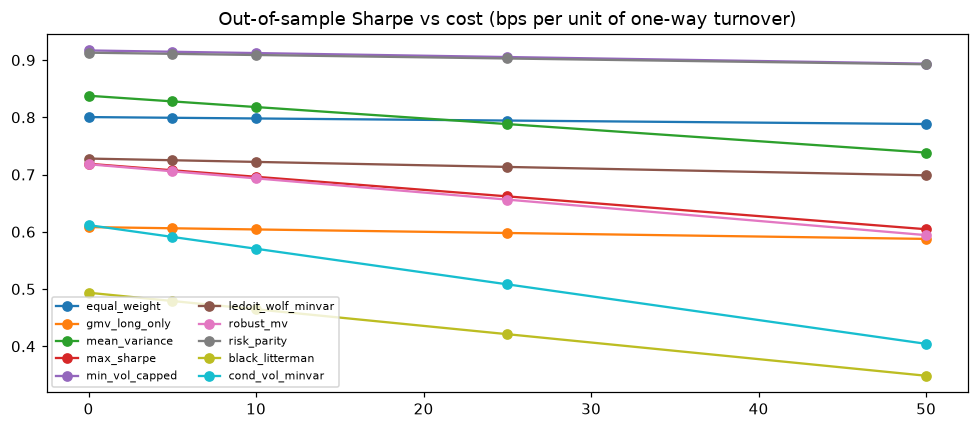

In [7]:
ax = cost_tab.T.plot(figsize=(9, 4), marker="o", title="Out-of-sample Sharpe vs cost (bps per unit of one-way turnover)")
ax.legend(fontsize=7, ncol=2)
fig = ax.get_figure()
plt.tight_layout()
fig.savefig(FIGURE_DIR / "oos_sharpe_vs_transaction_cost.png", dpi=150, bbox_inches="tight")

## 5. Robustness of the design itself

In [8]:
variants = {"roll504_21": dict(window=504, rebalance_every=21),
            "roll252_21": dict(window=252, rebalance_every=21),
            "roll756_63": dict(window=756, rebalance_every=63),
            "expand504_21": dict(window=504, rebalance_every=21, expanding=True)}
v_tab = {}
for k, kw in variants.items():
    r = walk_forward(returns, models, cost_bps=10, **kw)
    v_tab[k] = {m: ev.sharpe_ratio(r.net_returns[m]) for m in r.net_returns.columns}
window_sensitivity = pd.DataFrame(v_tab).round(3)
window_sensitivity.to_csv(TABLE_DIR / "oos_window_and_rebalance_sensitivity.csv", index_label="model")
window_sensitivity

,roll504_21,roll252_21,roll756_63,expand504_21
equal_weight,0.798,0.767,0.786,0.798
gmv_long_only,0.604,0.581,0.522,0.620
mean_variance,0.818,0.730,0.936,0.921
max_sharpe,0.696,0.696,0.985,0.944
min_vol_capped,0.912,0.824,0.908,0.961
ledoit_wolf_minvar,0.722,0.713,0.615,0.660
robust_mv,0.693,0.770,0.769,0.772
risk_parity,0.909,0.780,0.867,0.891
black_litterman,0.465,0.625,0.614,0.525
cond_vol_minvar,0.570,0.549,0.485,0.571


Do the model rankings survive changes in window length and estimation scheme? If the ranking of the top models changes with an arbitrary design choice, what does that say about the claim "model A is better than model B"?
Report this as a *rank-stability* statement, not as a single winner.

**Rank stability is partial, not decisive.** Capped minimum volatility is the most consistent top performer: it ranks **1st in three of four** setups and **3rd** in the other. Risk parity stays in the top four (**2nd, 2nd, 4th, 4th**), and mean-variance is also usually near the top (**3rd, 5th, 2nd, 3rd**).

Other rankings depend more on the setup. Max-Sharpe goes from **6th and 7th** with 21-day rebalancing to **1st and 2nd** in the 63-day and expanding-window runs. Equal weight is comparatively steady in the middle (**4th, 4th, 5th, 5th**). Conditional-volatility minimum variance is last or nearly last in every variant; GMV and Black–Litterman also tend to rank low.

So the results give some support to capped minimum volatility and risk parity being **consistently competitive in this sample**, but not to a universal claim that one model is best. In particular, `roll756_63` changes both the estimation window and rebalance frequency, so its ranking shift cannot be attributed to window length alone. These are net Sharpe rankings; the table does not show whether small score differences are statistically meaningful.

## 6. Regime-conditional out-of-sample performance

In [9]:
mkt = rd.market_proxy(returns, "SPY" if "SPY" in returns else None)
lab = rd.volatility_regimes_ex_ante(mkt)
rt = ev.regime_conditional_performance(res.net_returns, lab)
regime_sharpe = rt.pivot(index="model", columns="regime", values="sharpe").round(2)
regime_sharpe.to_csv(TABLE_DIR / "oos_regime_conditional_sharpe.csv", index_label="model")
regime_sharpe

regime,high_vol,low_vol,mid_vol
model,,,
black_litterman,0.49,0.97,0.14
cond_vol_minvar,0.43,1.41,0.27
equal_weight,0.89,1.26,0.45
gmv_long_only,0.47,1.33,0.41
ledoit_wolf_minvar,0.62,1.47,0.47
max_sharpe,0.40,1.87,0.77
mean_variance,0.69,1.76,0.52
min_vol_capped,0.98,1.29,0.67
risk_parity,0.99,1.44,0.51


**The regime results are strongly state-dependent.** These are Sharpe ratios for net out-of-sample returns within each volatility regime, not returns themselves.

- **High volatility:** Risk parity (**0.99**) and capped minimum volatility (**0.98**) lead; equal weight is also relatively strong (**0.89**). Max-Sharpe, robust MV, and Black–Litterman are much lower (**0.40, 0.41, 0.49**).
- **Low volatility:** Every model has a Sharpe above 1. Max-Sharpe (**1.87**), robust MV (**1.84**), and mean-variance (**1.76**) are strongest.
- **Mid volatility:** Sharpe ratios are lower across the board. Max-Sharpe leads (**0.77**), followed by capped minimum volatility (**0.67**); Black–Litterman is lowest (**0.14**).

There is **no model that leads in every regime**: risk parity and capped minimum volatility stand out in high volatility, while mean-sensitive optimizers look strongest in low volatility. That supports a regime-conditional reading, not a universal model winner.

The table omits regime observation counts and confidence intervals, so the apparent differences—especially in high-volatility periods, which may have fewer observations—should not be treated as statistically established. Also, the notebook labels regimes using 21-day rolling volatility and expanding historical thresholds. Since the rolling measure includes the current day’s return, these results are best read as **descriptive regime comparisons**, not as evidence that the regime could have been identified before that same day’s return.